# Taller: Evaluación de modelos y ajuste de hiperparámetros

**Machine Learning – Universidad Libre**
Rebeca Pedrozo Cueto

---

### Contenido

| Paso | Tema |
|---|---|
| 1 | Cargar datos y dividir en entrenamiento y prueba |
| 2 | Medir MAE, RMSE y R² en entrenamiento vs. prueba |
| 3 | Detectar el sobreajuste: polinomios de grado 1 a 15 |
| 4 | Validación cruzada: comparar 3 modelos |
| 5 | `GridSearchCV` y `RandomizedSearchCV` |
| 6 | Clasificación: matriz de confusión, F1 y AUC |

Se usan datasets incluidos en scikit-learn, así que **no hay que subir archivos**.
Solo ejecuta las celdas en orden.

## Paso 0 – Preparación

Importamos todo lo necesario y fijamos una semilla para que los resultados sean reproducibles.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes, load_breast_cancer
from sklearn.model_selection import (train_test_split, cross_val_score, cross_validate,
                                     KFold, GridSearchCV, RandomizedSearchCV)
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, f1_score,
                             roc_auc_score, RocCurveDisplay)

SEED = 42
np.random.seed(SEED)
plt.rcParams['figure.figsize'] = (6, 4)
print('Listo ✅')

Listo ✅


## Paso 1 – Cargar datos y dividir en entrenamiento y prueba

Usamos el dataset **diabetes** (regresión): 10 variables clínicas y, como objetivo,
un índice de progresión de la enfermedad.

División **80 % entrenamiento / 20 % prueba**. El conjunto de prueba se guarda y
**no se toca** hasta el final.

In [2]:
X, y = load_diabetes(return_X_y=True, as_frame=True)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED)

print(f'Variables: {list(X.columns)}')
print(f'Entrenamiento: {X_train.shape[0]} filas | Prueba: {X_test.shape[0]} filas')
X.head()

Variables: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']
Entrenamiento: 353 filas | Prueba: 89 filas


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


## Paso 2 – Medir MAE, RMSE y R² en entrenamiento vs. prueba

Tres métricas de regresión:

- **MAE**: error promedio en las mismas unidades que `y`. Fácil de interpretar.
- **RMSE**: parecido, pero castiga más los errores grandes.
- **R²**: proporción de la varianza explicada (1 = perfecto, 0 = tan bueno como predecir la media).

Comparamos los valores en entrenamiento y prueba: si en prueba son mucho peores,
hay **sobreajuste**.

In [3]:
def metricas(modelo, X, y):
    pred = modelo.predict(X)
    return {
        'MAE':  mean_absolute_error(y, pred),
        'RMSE': np.sqrt(mean_squared_error(y, pred)),
        'R2':   r2_score(y, pred),
    }

lr = LinearRegression().fit(X_train, y_train)

tabla = pd.DataFrame({
    'entrenamiento': metricas(lr, X_train, y_train),
    'prueba':        metricas(lr, X_test,  y_test),
}).round(3)
tabla

,entrenamiento,prueba
MAE,43.484,42.794
RMSE,53.559,53.853
R2,0.528,0.453


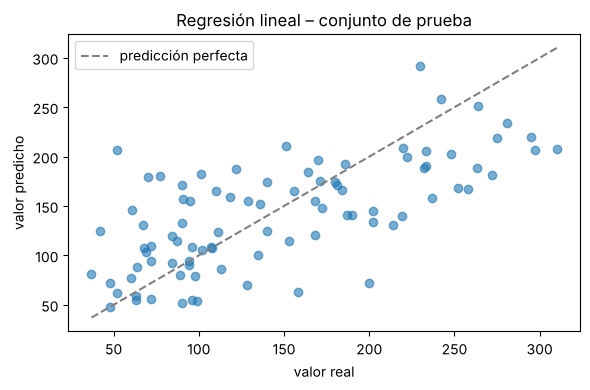

In [4]:
# Predicho vs. real en el conjunto de prueba
pred_test = lr.predict(X_test)

plt.scatter(y_test, pred_test, alpha=0.6)
lims = [y_test.min(), y_test.max()]
plt.plot(lims, lims, '--', color='gray', label='predicción perfecta')
plt.xlabel('valor real'); plt.ylabel('valor predicho')
plt.title('Regresión lineal – conjunto de prueba')
plt.legend(); plt.tight_layout(); plt.show()

Los valores de entrenamiento y prueba quedan muy parecidos, así que el modelo lineal
no está sobreajustado. El problema es otro: el R² ronda 0.5, o sea que el modelo se queda
corto para estos datos (subajuste). En el gráfico las predicciones siguen la tendencia
general, pero con bastante dispersión.

## Paso 3 – Detectar el sobreajuste: polinomios de grado 1 a 15

Para que el sobreajuste se vea con claridad usamos **una sola variable** (`bmi`, el
índice de masa corporal) y una **muestra reducida** de entrenamiento. Luego ajustamos
polinomios de grado 1 hasta 15 y medimos el RMSE en entrenamiento y en prueba.

La idea: al subir el grado el modelo se vuelve más flexible, el error de
entrenamiento baja siempre, pero el de prueba primero baja y después **sube**.

> El `MinMaxScaler` antes de `PolynomialFeatures` evita que las potencias altas se
> vuelvan números diminutos y rompan el cálculo.

In [5]:
# Una variable y una muestra reducida -> el efecto se ve mejor
Xb_train = X_train[['bmi']].iloc[:80]
yb_train = y_train.iloc[:80]
Xb_test, yb_test = X_test[['bmi']], y_test

grados = range(1, 16)
filas = []

for d in grados:
    modelo = make_pipeline(MinMaxScaler((-1, 1)),
                           PolynomialFeatures(d),
                           LinearRegression())
    modelo.fit(Xb_train, yb_train)
    filas.append({
        'grado': d,
        'RMSE_entrenamiento': np.sqrt(mean_squared_error(yb_train, modelo.predict(Xb_train))),
        'RMSE_prueba':        np.sqrt(mean_squared_error(yb_test,  modelo.predict(Xb_test))),
    })

res = pd.DataFrame(filas).set_index('grado')
res.round(2)

,RMSE_entrenamiento,RMSE_prueba
grado,,
1,62.29,64.75
2,62.09,64.66
3,61.68,65.16
4,61.66,64.70
5,61.51,75.87
6,61.30,88.00
7,61.27,173.65
8,61.14,705.09
9,60.97,1185.16


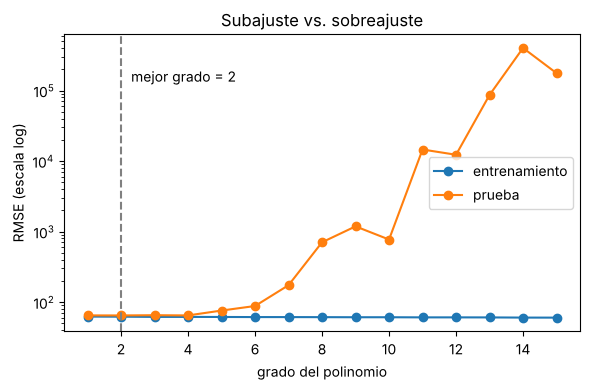

Mejor grado según prueba: 2 (RMSE = 64.66)
Grado 15: RMSE entrenamiento = 60.21 | prueba = 176243.58


In [6]:
plt.plot(res.index, res['RMSE_entrenamiento'], 'o-', label='entrenamiento')
plt.plot(res.index, res['RMSE_prueba'], 'o-', label='prueba')
plt.yscale('log')   # el error de prueba crece muchísimo: escala logarítmica

mejor = res['RMSE_prueba'].idxmin()
plt.axvline(mejor, ls='--', c='gray')
plt.text(mejor + 0.3, res['RMSE_prueba'].max() / 3, f'mejor grado = {mejor}')

plt.xlabel('grado del polinomio'); plt.ylabel('RMSE (escala log)')
plt.title('Subajuste vs. sobreajuste')
plt.legend(); plt.tight_layout(); plt.show()

print(f'Mejor grado según prueba: {mejor} (RMSE = {res.loc[mejor, "RMSE_prueba"]:.2f})')
print(f'Grado 15: RMSE entrenamiento = {res.loc[15, "RMSE_entrenamiento"]:.2f} '
      f'| prueba = {res.loc[15, "RMSE_prueba"]:.2f}')

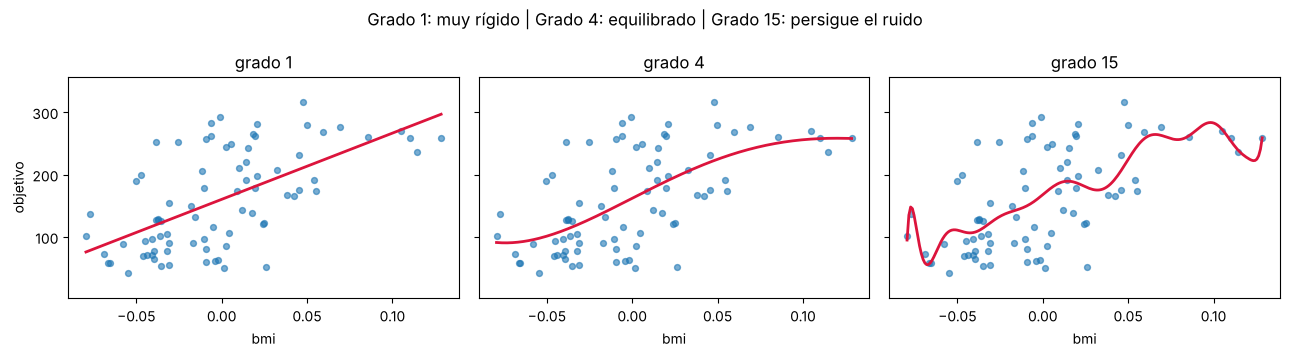

In [7]:
# ¿Cómo se ve cada ajuste? Comparamos tres grados sobre los mismos datos
rejilla = np.linspace(Xb_train['bmi'].min(), Xb_train['bmi'].max(), 200).reshape(-1, 1)
rejilla_df = pd.DataFrame(rejilla, columns=['bmi'])

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, d in zip(axes, [1, 4, 15]):
    modelo = make_pipeline(MinMaxScaler((-1, 1)),
                           PolynomialFeatures(d),
                           LinearRegression()).fit(Xb_train, yb_train)
    ax.scatter(Xb_train['bmi'], yb_train, s=18, alpha=0.6, label='datos')
    ax.plot(rejilla_df['bmi'], modelo.predict(rejilla_df), c='crimson', lw=2)
    ax.set_title(f'grado {d}')
    ax.set_xlabel('bmi')
axes[0].set_ylabel('objetivo')
axes[0].set_ylim(yb_train.min() - 40, yb_train.max() + 40)
plt.suptitle('Grado 1: muy rígido | Grado 4: equilibrado | Grado 15: persigue el ruido')
plt.tight_layout(); plt.show()

- Grados 1 y 2: error alto en los dos conjuntos. El modelo es demasiado rígido y hay
  subajuste.
- Grados intermedios: el error de prueba toca su mínimo, que es el mejor equilibrio.
- Grados altos: el error de entrenamiento sigue bajando despacio mientras el de prueba se
  dispara en órdenes de magnitud. Eso es sobreajuste, el modelo memoriza el ruido de la
  muestra y falla con datos nuevos.

Esa brecha creciente entre las dos curvas es la señal práctica del sobreajuste. En el
último gráfico se ve por qué: la curva de grado 15 se retuerce para pasar cerca de cada
punto.

## Paso 4 – Validación cruzada: comparar 3 modelos

Una sola partición puede ser afortunada. Con **K-Fold (k = 5)** dividimos el
entrenamiento en 5 partes, entrenamos 5 veces y promediamos, así la estimación es
mucho más estable.

Comparamos tres modelos de **familias distintas**, y para cada uno calculamos las
mismas tres métricas del Paso 2 (MAE, RMSE y R²):

| Modelo | Idea |
|---|---|
| `LinearRegression` | recta, sin regularización |
| `Ridge` | recta que penaliza coeficientes grandes (L2) |
| `DecisionTreeRegressor` | árbol de decisión: parte los datos en reglas, no supone linealidad |

Cada modelo va dentro de un `Pipeline` con `StandardScaler`, para que el escalado se
calcule **dentro de cada fold** y no haya fuga de datos. (El árbol no necesita escalado,
pero dejarlo en el pipeline mantiene la comparación pareja.)

In [8]:
modelos = {
    'LinearRegression': LinearRegression(),
    'Ridge (alpha=1)':  Ridge(alpha=1.0),
    'Árbol de decisión': DecisionTreeRegressor(random_state=SEED),
}

cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {'MAE':  'neg_mean_absolute_error',
           'RMSE': 'neg_root_mean_squared_error',
           'R2':   'r2'}

resumen = []
for nombre, m in modelos.items():
    pipe = Pipeline([('scaler', StandardScaler()), ('modelo', m)])
    r = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    resumen.append({
        'modelo':    nombre,
        'MAE':       -r['test_MAE'].mean(),
        'RMSE':      -r['test_RMSE'].mean(),
        'RMSE_desv':  r['test_RMSE'].std(),
        'R2':         r['test_R2'].mean(),
    })

cv_tabla = pd.DataFrame(resumen).set_index('modelo').round(3)
cv_tabla

,MAE,RMSE,RMSE_desv,R2
modelo,,,,
LinearRegression,45.048,55.395,2.361,0.480
Ridge (alpha=1),44.999,55.374,2.373,0.481
Árbol de decisión,62.273,81.041,10.184,-0.124


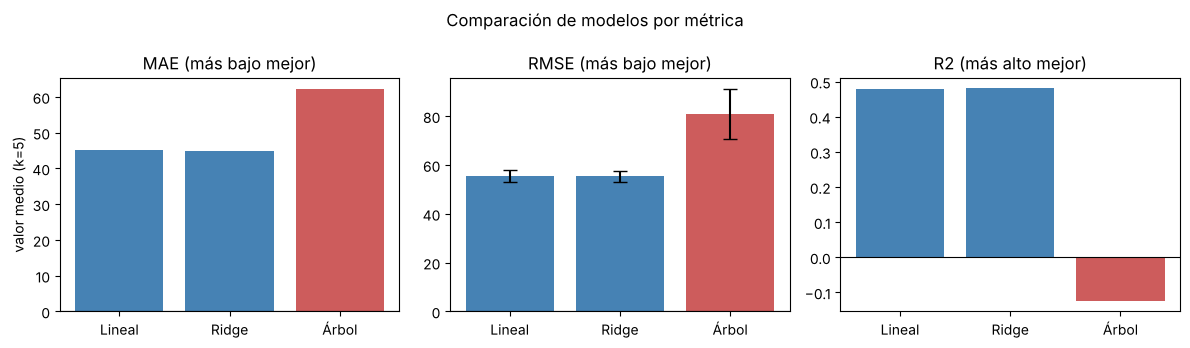

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
colores = ['steelblue', 'steelblue', 'indianred']

for ax, metrica in zip(axes, ['MAE', 'RMSE', 'R2']):
    err = cv_tabla['RMSE_desv'] if metrica == 'RMSE' else None
    ax.bar(range(len(cv_tabla)), cv_tabla[metrica], yerr=err, capsize=5, color=colores)
    ax.set_xticks(range(len(cv_tabla)))
    ax.set_xticklabels(['Lineal', 'Ridge', 'Árbol'])
    ax.set_title(metrica + (' (más alto mejor)' if metrica == 'R2' else ' (más bajo mejor)'))
    ax.axhline(0, color='black', lw=0.8)

axes[0].set_ylabel('valor medio (k=5)')
plt.suptitle('Comparación de modelos por métrica')
plt.tight_layout(); plt.show()

**¿Y si podamos el árbol?**

El árbol sin restricciones crece hasta separar casi cada observación. Limitando su
profundidad se vuelve más simple y debería generalizar mejor.

In [10]:
for prof in [2, 3, 5, None]:
    pipe = Pipeline([('scaler', StandardScaler()),
                     ('modelo', DecisionTreeRegressor(max_depth=prof, random_state=SEED))])
    r = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    etiqueta = f'max_depth={prof}' if prof else 'sin podar'
    print(f'{etiqueta:14s} RMSE={-r["test_RMSE"].mean():6.2f}   R2={r["test_R2"].mean():6.3f}')

max_depth=2    RMSE= 63.39   R2= 0.317
max_depth=3    RMSE= 65.05   R2= 0.277
max_depth=5    RMSE= 68.57   R2= 0.202
sin podar      RMSE= 81.04   R2=-0.124


Los dos modelos lineales quedan prácticamente iguales: MAE cerca de 45, RMSE cerca de
55 y R² alrededor de 0.48. Con estos datos la regularización casi no cambia el
desempeño.

El árbol sin podar queda bastante peor, y su **R² es negativo**, o sea que predice peor
que usar siempre el promedio de `y`. Es el mismo problema del Paso 3 en otro modelo: un
árbol que crece sin límite memoriza el entrenamiento. Al podarlo mejora bastante, y de
hecho entre más simple mejor: el mejor resultado es con profundidad 2. Aun así sigue por
debajo de los lineales, lo cual sugiere que la relación en estos datos es razonablemente
lineal.

Dos cosas que deja el paso. Una, comparar modelos de familias distintas dice mucho más
que comparar variantes del mismo. Y dos, conviene mirar la desviación junto con el
promedio: la del árbol es cuatro veces la de los lineales, así que además de peor es
menos estable.

## Paso 5 – `GridSearchCV` y `RandomizedSearchCV`

Ahora buscamos el mejor **hiperparámetro** (`alpha`) de forma automática.

- **`GridSearchCV`**: prueba *todas* las combinaciones de una lista. Exhaustivo pero costoso.
- **`RandomizedSearchCV`**: prueba *n* combinaciones al azar. Más rápido cuando el espacio es grande.

Las dos búsquedas usan validación cruzada internamente y **solo** los datos de entrenamiento.

In [11]:
# --- GridSearchCV sobre Ridge ---
pipe_ridge = Pipeline([('scaler', StandardScaler()), ('modelo', Ridge())])
malla = {'modelo__alpha': [0.001, 0.01, 0.1, 1, 10, 100, 1000]}

grid = GridSearchCV(pipe_ridge, malla, cv=cv,
                    scoring='neg_root_mean_squared_error')
grid.fit(X_train, y_train)

print('GridSearchCV')
print('  mejor alpha :', grid.best_params_['modelo__alpha'])
print(f'  RMSE (CV)   : {-grid.best_score_:.2f}')

pd.DataFrame(grid.cv_results_)[['param_modelo__alpha', 'mean_test_score']] \
  .assign(RMSE=lambda d: -d['mean_test_score']) \
  .drop(columns='mean_test_score').round(3)

GridSearchCV
  mejor alpha : 1
  RMSE (CV)   : 55.37


,param_modelo__alpha,RMSE
0,0.001,55.395
1,0.010,55.394
2,0.100,55.389
3,1.000,55.374
4,10.000,55.435
5,100.000,56.001
6,1000.000,64.386


In [12]:
# --- RandomizedSearchCV sobre Lasso ---
pipe_lasso = Pipeline([('scaler', StandardScaler()), ('modelo', Lasso(max_iter=10000))])
distrib = {'modelo__alpha': np.logspace(-3, 1, 100)}

rand = RandomizedSearchCV(pipe_lasso, distrib, n_iter=20, cv=cv,
                          scoring='neg_root_mean_squared_error',
                          random_state=SEED)
rand.fit(X_train, y_train)

print('RandomizedSearchCV')
print(f'  mejor alpha : {rand.best_params_["modelo__alpha"]:.4f}')
print(f'  RMSE (CV)   : {-rand.best_score_:.2f}')
print(f'  combinaciones probadas: 20 de 100 posibles')

RandomizedSearchCV
  mejor alpha : 0.1385
  RMSE (CV)   : 55.35
  combinaciones probadas: 20 de 100 posibles


Variables descartadas por Lasso: ['s3']


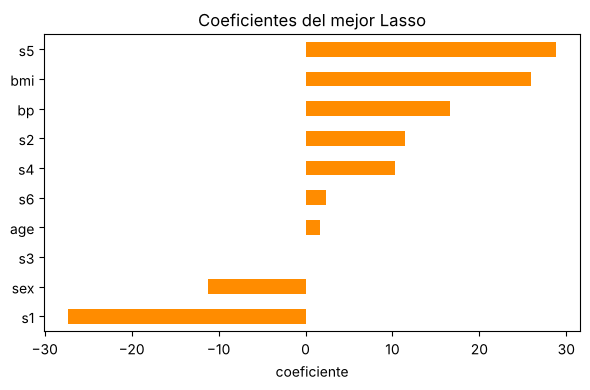

In [13]:
# Coeficientes que el Lasso dejó en cero (selección de variables)
coef = pd.Series(rand.best_estimator_['modelo'].coef_, index=X.columns)
print('Variables descartadas por Lasso:', list(coef[coef == 0].index) or 'ninguna')
coef.sort_values().plot.barh(color='darkorange')
plt.title('Coeficientes del mejor Lasso'); plt.xlabel('coeficiente')
plt.tight_layout(); plt.show()

In [14]:
# --- Evaluación final: el conjunto de prueba se usa UNA sola vez ---
final = grid.best_estimator_   # el mejor Ridge encontrado

comparacion = pd.DataFrame({
    'modelo base (lineal)': metricas(lr, X_test, y_test),
    'mejor Ridge (Grid)':   metricas(final, X_test, y_test),
}).round(3)
comparacion

,modelo base (lineal),mejor Ridge (Grid)
MAE,42.794,42.812
RMSE,53.853,53.777
R2,0.453,0.454


`GridSearchCV` recorre la malla completa y `RandomizedSearchCV` llega a un resultado
parecido probando solo una fracción de los valores, que es su ventaja cuando hay muchos
hiperparámetros. El Lasso además pone en cero algunos coeficientes, o sea que hace
selección de variables por sí solo.

El modelo ajustado mejora poco al base. Eso es coherente con el Paso 4: con estos datos
los modelos lineales ya están cerca de su techo, así que afinar el alpha cambia poco.

## Paso 6 – Clasificación: matriz de confusión, F1 y AUC

Cambiamos de problema: dataset **breast_cancer**, donde hay que predecir si un tumor
es benigno (1) o maligno (0).

Métricas de clasificación:

- **Matriz de confusión**: aciertos y errores por clase.
- **Precisión**: de lo que predije positivo, ¿cuánto lo era?
- **Recall**: de los positivos reales, ¿cuántos detecté?
- **F1**: promedio armónico de las dos; útil con clases desbalanceadas.
- **AUC**: qué tan bien el modelo *ordena* los casos, sin depender del umbral.

In [15]:
Xc, yc = load_breast_cancer(return_X_y=True, as_frame=True)

Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    Xc, yc, test_size=0.20, stratify=yc, random_state=SEED)

clf = Pipeline([('scaler', StandardScaler()),
                ('modelo', LogisticRegression(max_iter=1000))]).fit(Xc_train, yc_train)

pred  = clf.predict(Xc_test)
proba = clf.predict_proba(Xc_test)[:, 1]

print(f'F1  = {f1_score(yc_test, pred):.3f}')
print(f'AUC = {roc_auc_score(yc_test, proba):.3f}')
print()
print(classification_report(yc_test, pred,
      target_names=['maligno (0)', 'benigno (1)'], digits=3))

F1  = 0.986
AUC = 0.995

              precision    recall  f1-score   support

 maligno (0)      0.976     0.976     0.976        42
 benigno (1)      0.986     0.986     0.986        72

    accuracy                          0.982       114
   macro avg      0.981     0.981     0.981       114
weighted avg      0.982     0.982     0.982       114



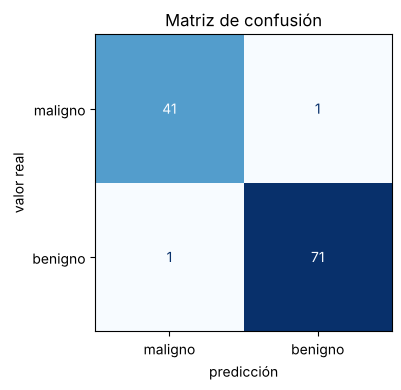

In [16]:
ConfusionMatrixDisplay.from_estimator(
    clf, Xc_test, yc_test,
    display_labels=['maligno', 'benigno'], cmap='Blues', colorbar=False)
plt.xlabel('predicción'); plt.ylabel('valor real')
plt.title('Matriz de confusión'); plt.tight_layout(); plt.show()

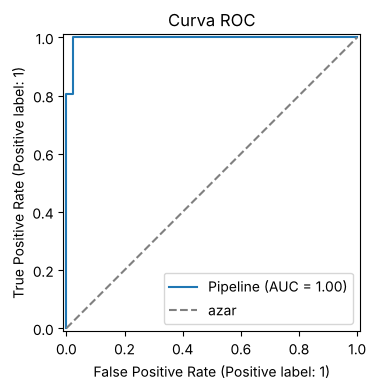

In [17]:
RocCurveDisplay.from_estimator(clf, Xc_test, yc_test)
plt.plot([0, 1], [0, 1], '--', c='gray', label='azar')
plt.title('Curva ROC'); plt.legend(); plt.tight_layout(); plt.show()

### Efecto del umbral de decisión

Por defecto se clasifica como positivo si la probabilidad ≥ 0.5. Al mover ese umbral
se cambia el balance entre precisión y recall. En un diagnóstico médico interesa un
**recall alto** en la clase grave, aunque cueste algunos falsos positivos.

In [18]:
from sklearn.metrics import precision_score, recall_score

filas = []
for t in (0.3, 0.5, 0.7, 0.9):
    p = (proba >= t).astype(int)
    filas.append({'umbral': t,
                  'precisión': precision_score(yc_test, p),
                  'recall':    recall_score(yc_test, p),
                  'F1':        f1_score(yc_test, p)})

pd.DataFrame(filas).set_index('umbral').round(3)

,precisión,recall,F1
umbral,,,
0.3,0.973,1.000,0.986
0.5,0.986,0.986,0.986
0.7,0.985,0.931,0.957
0.9,0.984,0.847,0.910


El clasificador funciona muy bien (F1 y AUC cercanos a 1) y la matriz de confusión
muestra pocos errores. Al bajar el umbral sube el recall y baja la precisión; al subirlo
pasa lo contrario. El AUC se mantiene igual con cualquier umbral porque mide la capacidad
de ordenamiento del modelo.

## Conclusiones

1. Entrenamiento y prueba se separan al inicio, y el conjunto de prueba se usa una sola
   vez al final.
2. MAE y RMSE dicen cuánto se equivoca el modelo y R² qué parte de la variabilidad
   explica. Los tres se reportan en entrenamiento y en prueba.
3. Con polinomios de grado 1 a 15 aparece el patrón clásico del sobreajuste: el error de
   entrenamiento baja sin parar mientras el de prueba vuelve a subir.
4. Con k = 5 la comparación entre modelos es más confiable que con una sola partición, y
   la desviación indica qué tan estable es el resultado. El árbol sin podar lo muestra:
   peor promedio y mucha más variabilidad entre folds.
5. `GridSearchCV` es exhaustivo y `RandomizedSearchCV` consigue resultados similares con
   menos pruebas. Las dos van dentro de un `Pipeline` para evitar fuga de datos.
6. La exactitud sola se queda corta en clasificación. La matriz de confusión muestra qué
   tipo de error se comete, F1 equilibra precisión y recall, y el AUC resume el desempeño
   para todos los umbrales.

---

### Reto – Proyecto del curso (base de tiendas)

1. Carga tu base preprocesada y define la variable objetivo.
2. Haz la partición entrenamiento/prueba y evalúa un modelo base con validación cruzada.
3. Ajusta hiperparámetros con `GridSearchCV` dentro de un `Pipeline` (evita la fuga de datos).
4. Reporta MAE, RMSE y R² en prueba y justifica la elección del modelo.